# AFM 244 — Week 11 Team Exercise
## Time-Series Revenue Forecast: Target Corporation (TGT)

**Company:** Target Corporation (ticker TGT), a large U.S. general-merchandise retailer.

**Goal:** Build a time-series forecasting model for Target's quarterly revenue, using a time trend plus dummy variables to capture seasonality. We train on the first 75% of history, test on the last 25%, measure accuracy with **MAPE**, and then forecast the next **4 quarters**.

**Workflow (same steps as the class demo):**
- Step 0 — visualize the data to spot patterns
- Step 1 — introduce *time* as an independent variable
- Step 2 — introduce *dummy variables* (seasonality)
- Step 3 — multiple-regression modelling, train/test, and forecast

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.2f}'.format

### Load the data and isolate Target

In [ ]:
qSales = pd.read_csv('qSales_2024.csv')
qSales['datadate'] = pd.to_datetime(qSales['datadate'])

# isolate Target Corporation
tgt = qSales.loc[qSales['tic'] == 'TGT'].copy().reset_index(drop=True)
print('rows:', len(tgt), '| missing revenue:', tgt['saleq'].isna().sum())
tgt[['datadate','fyearq','fqtr','saleq']].head()

rows: 93 | missing revenue: 0


,datadate,fyearq,fqtr,saleq
0,2001-01-31,2000,4,12324.00
1,2001-04-30,2001,1,8334.00
2,2001-07-31,2001,2,8941.00
3,2001-10-31,2001,3,9331.00
4,2002-01-31,2001,4,13220.00


Note on Target's fiscal calendar: Target's fiscal year ends in late January, so **fiscal Q4 is the Nov–Jan holiday quarter**, the seasonal peak. That is the pattern our dummy variables will capture.

### Step 0 — Visualize

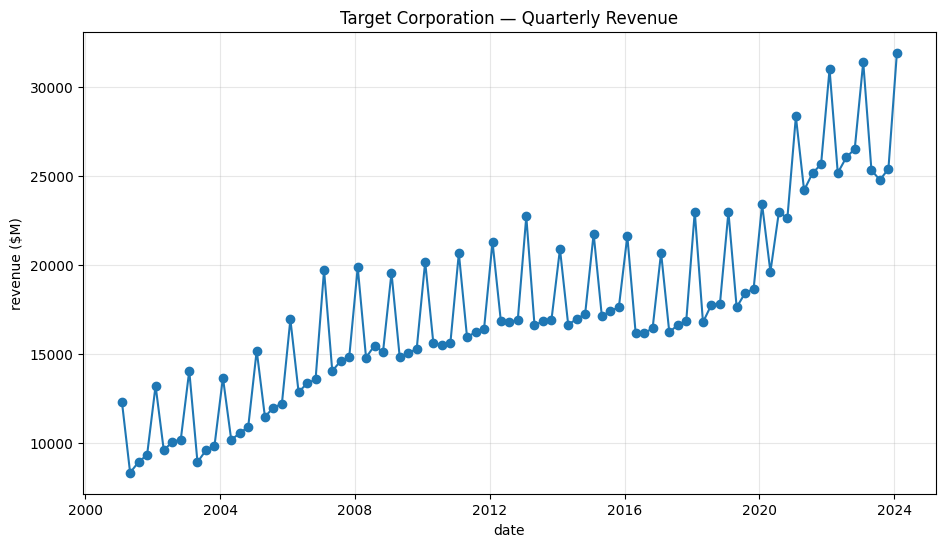

In [ ]:
plt.figure(figsize=(11,6))
plt.title('Target Corporation — Quarterly Revenue')
plt.xlabel('date'); plt.ylabel('revenue ($M)')
plt.plot(tgt['datadate'], tgt['saleq'], marker='o')
plt.grid(alpha=0.3)
plt.show()

The plot shows two clear features: a **gentle upward trend** over time, and a **repeating seasonal spike every 4th quarter** (the holiday quarter). A time trend alone will miss the sawtooth, so we add seasonal dummies.

### Step 1 — Add the time component

In [ ]:
tgt['time'] = range(1, len(tgt) + 1)   # 1, 2, 3, ... one per quarter
tgt[['datadate','fqtr','saleq','time']].head()

,datadate,fqtr,saleq,time
0,2001-01-31,4,12324.00,1
1,2001-04-30,1,8334.00,2
2,2001-07-31,2,8941.00,3
3,2001-10-31,3,9331.00,4
4,2002-01-31,4,13220.00,5


### Step 2 — Build dummy variables (seasonality)
We use quarter dummies with **Q1 as the baseline**. This gives us three seasonal dummies (Q2, Q3, Q4), comfortably meeting the *"at least 2 dummy variables"* requirement. We also add a **Q4 interaction** (`time × q4`) so the linear model can let the holiday premium grow over time.

In [ ]:
tgt['q2'] = np.where(tgt['fqtr'] == 2, 1, 0)
tgt['q3'] = np.where(tgt['fqtr'] == 3, 1, 0)
tgt['q4'] = np.where(tgt['fqtr'] == 4, 1, 0)   # holiday quarter
tgt['q4_int'] = tgt['time'] * tgt['q4']        # interaction: holiday premium x time

tgt.groupby('fqtr')['saleq'].mean().round(0)

fqtr
1   15868.00
2   16408.00
3   16608.00
4   21099.00
Name: saleq, dtype: float64

Average revenue by fiscal quarter confirms Q4 (holiday) sits far above the other three quarters.

### Split into training (75%) and testing (25%)

In [ ]:
cut = int(0.75 * len(tgt))
dt4training = tgt[:cut].copy()   # first 75%
dt4testing  = tgt[cut:].copy()   # last 25%

print('train:', len(dt4training), 'quarters (', dt4training['datadate'].min().date(),
      '->', dt4training['datadate'].max().date(), ')')
print('test :', len(dt4testing), 'quarters (', dt4testing['datadate'].min().date(),
      '->', dt4testing['datadate'].max().date(), ')')

train: 69 quarters ( 2001-01-31 -> 2018-01-31 )
test : 24 quarters ( 2018-04-30 -> 2024-01-31 )


### A MAPE helper
MAPE = Mean Absolute Percentage Error, the average size of our forecast error as a % of actual revenue. Lower is better.

In [ ]:
def mape(actual, forecast):
    actual, forecast = np.array(actual, float), np.array(forecast, float)
    return np.mean(np.abs((actual - forecast) / actual)) * 100

### Step 3a - Model 1: Linear time-trend + seasonal dummies



In [ ]:
cols_lin = ['time', 'q2', 'q3', 'q4', 'q4_int']

x = sm.add_constant(dt4training[cols_lin])
y = dt4training['saleq']
model_linear = sm.OLS(y, x).fit()
model_linear.params

const    9318.92
time      134.67
q2        216.50
q3        262.54
q4       4158.53
q4_int     15.75
dtype: float64

**Model 1 (linear):**

`revenue = const + b1·time + b2·q2 + b3·q3 + b4·q4 + b5·(time·q4)`

In [ ]:
x_test = sm.add_constant(dt4testing[cols_lin])
pred_linear = model_linear.predict(x_test)
mape_linear = mape(dt4testing['saleq'], pred_linear)
print(f'Model 1 (linear) test MAPE: {mape_linear:.2f}%')

Model 1 (linear) test MAPE: 11.95%


### Step 3b - Model 2 (refinement): Log-linear model
To **minimize MAPE**, we model the **log of revenue**. A log model treats seasonality as a *percentage* effect (multiplicative) rather than a fixed dollar amount, which fits retail revenue better and reduces the error. We fit `log(revenue) ~ time + q2 + q3 + q4`, then exponentiate the predictions back to dollars.

In [ ]:
cols_log = ['time', 'q2', 'q3', 'q4']

x_log = sm.add_constant(dt4training[cols_log])
y_log = np.log(dt4training['saleq'])
model_log = sm.OLS(y_log, x_log).fit()
model_log.params

const   9.18
time    0.01
q2      0.02
q3      0.02
q4      0.30
dtype: float64

In [ ]:
x_test_log = sm.add_constant(dt4testing[cols_log])
pred_log = np.exp(model_log.predict(x_test_log))   # back to $ from log
mape_log = mape(dt4testing['saleq'], pred_log)
print(f'Model 2 (log-linear) test MAPE: {mape_log:.2f}%')

Model 2 (log-linear) test MAPE: 8.97%


### Compare the two models

In [ ]:
print(f'Model 1  linear      test MAPE: {mape_linear:5.2f}%')
print(f'Model 2  log-linear  test MAPE: {mape_log:5.2f}%')
print(f'Training R-squared (log model): {model_log.rsquared:.3f}')

Model 1  linear      test MAPE: 11.95%
Model 2  log-linear  test MAPE:  8.97%
Training R-squared (log model): 0.865


The **log-linear model wins** on MAPE, so we use it for the forecast.

### Visualize: actual vs. forecast on the test set

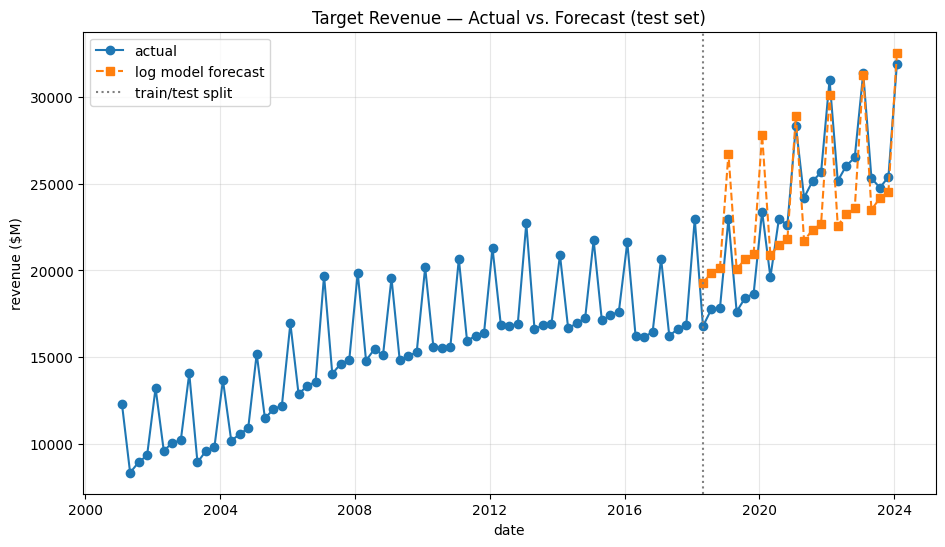

In [ ]:
plt.figure(figsize=(11,6))
plt.title('Target Revenue — Actual vs. Forecast (test set)')
plt.xlabel('date'); plt.ylabel('revenue ($M)')
plt.plot(tgt['datadate'], tgt['saleq'], marker='o', label='actual')
plt.plot(dt4testing['datadate'], pred_log, marker='s', linestyle='--', label='log model forecast')
plt.axvline(dt4testing['datadate'].min(), color='grey', linestyle=':', label='train/test split')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Forecast the next 4 quarters
We refit the winning (log-linear) model on **all** available history, then predict Target's next four fiscal quarters. Target's last data point is fiscal Q4 2023 (Jan 31 2024, time = 93), so the next four are time 94–97:

| Quarter | Approx. end date | fqtr |
|---|---|---|
| FY2024 Q1 | 2024-04-30 | 1 |
| FY2024 Q2 | 2024-07-31 | 2 |
| FY2024 Q3 | 2024-10-31 | 3 |
| FY2024 Q4 | 2025-01-31 | 4 |

In [ ]:
# refit log model on the full dataset
x_full = sm.add_constant(tgt[cols_log])
model_log_full = sm.OLS(np.log(tgt['saleq']), x_full).fit()

future = pd.DataFrame({
    'label': ['FY24 Q1','FY24 Q2','FY24 Q3','FY24 Q4'],
    'date':  ['2024-04-30','2024-07-31','2024-10-31','2025-01-31'],
    'time':  [94, 95, 96, 97],
    'fqtr':  [1, 2, 3, 4],
})
future['q2'] = (future['fqtr']==2).astype(int)
future['q3'] = (future['fqtr']==3).astype(int)
future['q4'] = (future['fqtr']==4).astype(int)

x_future = sm.add_constant(future[cols_log], has_constant='add')
pr = model_log_full.get_prediction(x_future).summary_frame(alpha=0.2)  # 80% interval

future['forecast_$M']   = np.exp(pr['mean']).round(0)
future['low_80%_$M']    = np.exp(pr['obs_ci_lower']).round(0)
future['high_80%_$M']   = np.exp(pr['obs_ci_upper']).round(0)
future[['label','date','time','forecast_$M','low_80%_$M','high_80%_$M']]

,label,date,time,forecast_$M,low_80%_$M,high_80%_$M
0,FY24 Q1,2024-04-30,94,24481.00,21516.00,27856.00
1,FY24 Q2,2024-07-31,95,25348.00,22278.00,28843.00
2,FY24 Q3,2024-10-31,96,25684.00,22572.00,29224.00
3,FY24 Q4,2025-01-31,97,33523.00,29460.00,38147.00


### Results summary

- **Best model:** log-linear time trend with quarterly seasonal dummies (Q1 baseline).
- **Test-set accuracy:** MAPE ≈ 9% (vs. ≈ 12% for the plain linear model).
- **Next 4 quarters (point forecast):** ~\$24.5B, \$25.3B, \$25.7B, and \$33.5B, with the holiday quarter (FY24 Q4) again the clear peak, consistent with Target's historical seasonality.

See the accompanying memo for the write-up of how the model was built and its predictive capabilities and limitations.